# Notebook 04 — Diagnostica Modello AE (Compatta)

> **Obiettivo:** capire **perché** l'autoencoder addestrato (`ae_baseline.pth`) non separa normal da anomalo in anomaly detection.

> **Principi guida:**
> - **Read-only:** niente scrittura su `src/`, `config/`, `data/processed/` o checkpoint.
> - **Output solo a schermo:** nessun file salvato localmente.
> - **Seed fissato:** `set_seed(42)` da `src.utils.seed`.
> - **Prevalenza** sempre mostrata accanto alle AUC.
> - **Test set:** usato solo per conferma finale, mai per calibrare soglie.
> - **Forma:** ogni sezione = 1 markdown (cosa/perché/come interpretare) + 1 codice (eseguibile autonomamente).


## Sezione 0 — Setup globale

**Cosa:** carica config, dati processati, loader, modello con filtro shape compatibile, device, prevalenza.
**Perché:** tutte le sezioni successive dipendono da queste variabili.
**Come interpretare:** se il checkpoint ha architettura diversa (shape mismatch), il filtro carica solo i tensori compatibili.

In [25]:
"""Sezione 0 — Setup globale: carica config, dati, modello, loader."""
try:
    SEED
except NameError:
    SEED = 42
set_seed(SEED)

import os, sys
from pathlib import Path
import numpy as np
import pandas as pd
import torch

CWD = os.getcwd()
if "notebooks" in CWD:
    PROJECT_ROOT = os.path.dirname(CWD)
else:
    PROJECT_ROOT = CWD
os.chdir(PROJECT_ROOT)
sys.path.insert(0, PROJECT_ROOT)

from src.utils.seed import set_seed
from src.utils.config import load_config, get_param
from src.data.dataset import build_loader
from src.models.autoencoder import SequenceAutoencoder

config = load_config()
processed_dir = Path(PROJECT_ROOT) / "data" / "processed"

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# --- Carica dati processati ---
train_arr = np.load(processed_dir / "train.npy")
val_normal_arr = np.load(processed_dir / "val_normal.npy")
val_anomaly_arr = np.load(processed_dir / "val_anomaly.npy")
test_normal_arr = np.load(processed_dir / "test_normal.npy")
test_anomaly_arr = np.load(processed_dir / "test_anomaly.npy")

scaled = {"train": train_arr, "val_normal": val_normal_arr,
         "val_anomaly": val_anomaly_arr, "test_normal": test_normal_arr,
         "test_anomaly": test_anomaly_arr}

train_data = train_arr
val_normal_data = val_normal_arr
val_anomaly_data = val_anomaly_arr
test_normal_data = test_normal_arr
test_anomaly_data = test_anomaly_arr

selected_cols = np.load(processed_dir / "selected_columns.npy", allow_pickle=True)
feature_names = [str(c) for c in selected_cols]

W = int(get_param(config, "model.window_size", 16))
batch_size = int(get_param(config, "training.batch_size", 256))
input_dim = int(get_param(config, "model.input_dim", 86))
latent_dim = int(get_param(config, "model.latent_dim", 16))

train_loader = build_loader(train_arr, window_size=W, batch_size=batch_size, label=0, shuffle=True, num_workers=0)
val_normal_loader = build_loader(val_normal_arr, window_size=W, batch_size=batch_size, label=0, num_workers=0)
val_anomaly_loader = build_loader(val_anomaly_arr, window_size=W, batch_size=batch_size, label=1, num_workers=0)
test_normal_loader = build_loader(test_normal_arr, window_size=W, batch_size=batch_size, label=0, num_workers=0)
test_anomaly_loader = build_loader(test_anomaly_arr, window_size=W, batch_size=batch_size, label=1, num_workers=0)

model = SequenceAutoencoder(input_dim=input_dim, window_size=W, latent_dim=latent_dim)
ckpt_path = Path(PROJECT_ROOT) / "reports" / "checkpoints" / "ae_baseline.pth"
if ckpt_path.exists():
    ckpt = torch.load(ckpt_path, map_location="cpu")
    ckpt_sd = ckpt["model_state_dict"]
    model_sd = model.state_dict()
    compatible = {k: v for k, v in ckpt_sd.items() if k in model_sd and v.shape == model_sd[k].shape}
    model.load_state_dict(compatible, strict=False)
    print("Modello caricato da %s (%d/%d tensori compatibili)" % (ckpt_path, len(compatible), len(ckpt_sd)))
else:
    print("ATTENZIONE: checkpoint non trovato a %s" % ckpt_path)
model.to(DEVICE)
model.eval()

val_prev = len(val_anomaly_arr) / (len(val_normal_arr) + len(val_anomaly_arr))
test_prev = len(test_anomaly_arr) / (len(test_normal_arr) + len(test_anomaly_arr))
val_prevalence = val_prev
test_prevalence = test_prev

print("SETUP GLOBALE completato.")
print("  input_dim=%d, W=%d, latent_dim=%d" % (input_dim, W, latent_dim))
print("  train=%d, val_normal=%d, val_anomaly=%d, test_normal=%d, test_anomaly=%d" % (len(train_arr), len(val_normal_arr), len(val_anomaly_arr), len(test_normal_arr), len(test_anomaly_arr)))
print("  device=%s" % DEVICE)

Modello caricato da c:\Users\ungol\OneDrive\Desktop\Ing-Inf-PoliTo\secondo anno\secondo semestre\Machine Learning in Application\project\AM01\AM01-Detection-of-Anomalous-Behaviour-in-Industrial-Robot\reports\checkpoints\ae_baseline.pth (13/16 tensori compatibili)
SETUP GLOBALE completato.
  input_dim=86, W=256, latent_dim=32
  train=163654, val_normal=35068, val_anomaly=20769, test_normal=35070, test_anomaly=20769
  device=cpu


## Sezione 1 — Baseline MAE_zero vs MAE_AE

**Cosa:** confronta l'errore MAE dell'autoencoder con quello di un baseline che predice sempre la media per-canale del train (MAE_zero).
**Perché:** se MAE_AE ≈ MAE_zero l'autoencoder non impara; se MAE_AE ≪ MAE_zero impara a ricostruire.
**Come interpretare:** ratio MAE_AE/MAE_zero > 0.8 → underfitting; AUC direct ≈ 0.5 e inverted > 0.5 → errore invertito (anomalie ricostruite meglio).

In [26]:
"""Sezione 1 — Baseline MAE_zero vs MAE_AE."""
try:
    SEED
except NameError:
    SEED = 42
set_seed(SEED)

# --- Compute per-channel mean from train ---
train_flat = train_data
channel_means = train_flat.mean(axis=0)
print("Media per-canale del train: shape=%s" % str(channel_means.shape))
print("Max |media|: %.6e (dovrebbe ≈ 0 su dati standardizzati)" % np.abs(channel_means).max())

# --- MAE_ZERO: mean per-channel error if we predict channel_means ---
def compute_mae_zero(loader, channel_means, device=DEVICE):
    errors = []
    for batch in loader:
        x = batch[0] if isinstance(batch, (list, tuple)) else batch
        x = x.to(device)
        x_pred = np.broadcast_to(channel_means, x.shape)
        x_np = x.cpu().numpy()
        mae_per_window = np.abs(x_np - x_pred).mean(axis=(1, 2))
        errors.append(mae_per_window)
    return np.concatenate(errors)

print("\nCalcolo MAE_zero...")
mae_zero_train = compute_mae_zero(train_loader, channel_means)
mae_zero_val_normal = compute_mae_zero(val_normal_loader, channel_means)
mae_zero_val_anomaly = compute_mae_zero(val_anomaly_loader, channel_means)

print("  MAE_zero_train:        mean=%.6f" % mae_zero_train.mean())
print("  MAE_zero_val_normal:   mean=%.6f" % mae_zero_val_normal.mean())
print("  MAE_zero_val_anomaly:  mean=%.6f" % mae_zero_val_anomaly.mean())

# --- MAE_AE: real MAE from autoencoder ---
from src.models.autoencoder import compute_errors_on_loader

mae_ae_train = compute_errors_on_loader(model, train_loader, DEVICE, metric="mae")
mae_ae_val_normal = compute_errors_on_loader(model, val_normal_loader, DEVICE, metric="mae")
mae_ae_val_anomaly = compute_errors_on_loader(model, val_anomaly_loader, DEVICE, metric="mae")

print("\n  MAE_AE_train:          mean=%.6f" % mae_ae_train.mean())
print("  MAE_AE_val_normal:     mean=%.6f" % mae_ae_val_normal.mean())
print("  MAE_AE_val_anomaly:    mean=%.6f" % mae_ae_val_anomaly.mean())

# --- Ratios ---
ratio_val_normal = mae_ae_val_normal.mean() / mae_zero_val_normal.mean()
ratio_val_anomaly = mae_ae_val_anomaly.mean() / mae_zero_val_anomaly.mean()
print("\n  Ratio MAE_AE/MAE_zero (val_normal):  %.4f" % ratio_val_normal)
print("  Ratio MAE_AE/MAE_zero (val_anomaly): %.4f" % ratio_val_anomaly)

# --- AUC comparison ---
from sklearn.metrics import roc_auc_score
from src.evaluation.metrics import calculate_auc

val_labels = np.concatenate([np.zeros(len(mae_ae_val_normal)), np.ones(len(mae_ae_val_anomaly))])
err_combined = np.concatenate([mae_ae_val_normal, mae_ae_val_anomaly])
auc_ae = calculate_auc(val_labels, err_combined)

mae_zero_combined = np.concatenate([mae_zero_val_normal, mae_zero_val_anomaly])
auc_zero = calculate_auc(val_labels, mae_zero_combined)

auc_ae_inv = calculate_auc(val_labels, -err_combined)
auc_zero_inv = calculate_auc(val_labels, -mae_zero_combined)

print("\n--- AUC VALIDATION (prevalenza=%.4f) ---" % val_prevalence)
print("  AE MAE (direct):      ROC-AUC=%.4f, PR-AUC=%.4f" % (auc_ae['roc_auc'], auc_ae['pr_auc']))
print("  AE MAE (inverted):    ROC-AUC=%.4f, PR-AUC=%.4f" % (auc_ae_inv['roc_auc'], auc_ae_inv['pr_auc']))
print("  Zero MAE (direct):    ROC-AUC=%.4f, PR-AUC=%.4f" % (auc_zero['roc_auc'], auc_zero['pr_auc']))
print("  Zero MAE (inverted):  ROC-AUC=%.4f, PR-AUC=%.4f" % (auc_zero_inv['roc_auc'], auc_zero_inv['pr_auc']))

# Interpretazione
print("\n--- Interpretazione ---")
if ratio_val_anomaly > 0.8:
    print("  → Ratio > 0.8: AE NON impara (underfitting). MAE_AE ≈ MAE_zero.")
elif ratio_val_anomaly < 0.3:
    print("  → Ratio < 0.3: AE impara a ricostruire (MAE_AE ≪ MAE_zero).")
    if auc_ae_inv['roc_auc'] > 0.65:
        print("  → AUC inverted > 0.65: segno invertito (errore basso = anomalo).")
    elif auc_ae['roc_auc'] > 0.55:
        print("  → AUC direct > 0.55: errore alto = anomalo (discriminativo).")
    else:
        print("  → AUC ≈ 0.5 (direct e inverted): AE impara ma ampiezza non separa classi.")
else:
    print("  → Ratio 0.3-0.8: AE impara parzialmente.")

Media per-canale del train: shape=(86,)
Max |media|: 1.000000e+00 (dovrebbe ≈ 0 su dati standardizzati)

Calcolo MAE_zero...
  MAE_zero_train:        mean=0.206876
  MAE_zero_val_normal:   mean=0.211907
  MAE_zero_val_anomaly:  mean=0.187281

  MAE_AE_train:          mean=0.338816
  MAE_AE_val_normal:     mean=0.344780
  MAE_AE_val_anomaly:    mean=0.330823

  Ratio MAE_AE/MAE_zero (val_normal):  1.6270
  Ratio MAE_AE/MAE_zero (val_anomaly): 1.7664

--- AUC VALIDATION (prevalenza=0.3720) ---
  AE MAE (direct):      ROC-AUC=0.2090, PR-AUC=0.2423
  AE MAE (inverted):    ROC-AUC=0.7910, PR-AUC=0.7256
  Zero MAE (direct):    ROC-AUC=0.1844, PR-AUC=0.2402
  Zero MAE (inverted):  ROC-AUC=0.8156, PR-AUC=0.7224

--- Interpretazione ---
  → Ratio > 0.8: AE NON impara (underfitting). MAE_AE ≈ MAE_zero.


## Sezione 2 — Errore per canale

**Cosa:** calcola MAE per canale su val_normal e val_anomaly usando compute_reconstruction_error(reduction='none').
**Perché:** vede quali canali separano normal da anomalo e se le anomalie hanno errore più alto o più basso (errore invertito).
**Come interpretare:** se alcune feature hanno MAE su anomalie più basso che su normal → errore invertito (AE ricostruisce meglio le anomalie).

In [27]:
"""Sezione 2 — Errore per canale."""
try:
    SEED
except NameError:
    SEED = 42
set_seed(SEED)

# --- Errore per canale su val (usa model.forward direttamente) ---
def channel_errors_from_loader(loader, model, device):
    model.eval()
    all_errs = []
    with torch.no_grad():
        for batch in loader:
            x = batch[0] if isinstance(batch, (list, tuple)) else batch
            x = x.to(device)
            x_pred = model(x)  # forward gestisce (B, W, input_dim) → (B, W, input_dim)
            diff = torch.abs(x - x_pred)  # (B, W, input_dim)
            all_errs.append(diff.cpu().numpy())
    return np.concatenate(all_errs, axis=0)  # (n, W, input_dim)

val_norm_err = channel_errors_from_loader(val_normal_loader, model, DEVICE)
val_anom_err = channel_errors_from_loader(val_anomaly_loader, model, DEVICE)

# val_norm_err: (n_norm, W, input_dim) ; val_anom_err: (n_anom, W, input_dim)
channel_norm_err = val_norm_err.mean(axis=(0, 1))
channel_anom_err = val_anom_err.mean(axis=(0, 1))

print("=== ERRORE PER CANALE (val set) ===")
print("%-30s %12s %12s %12s %10s" % ("Feature", "MAE_norm", "MAE_anom", "Diff", "Ratio"))
for i, name in enumerate(feature_names[:input_dim]):
    n = channel_norm_err[i]
    a = channel_anom_err[i]
    diff = a - n
    ratio = a / (n + 1e-12)
    marker = " <-- INVERTITO" if a < n else ""
    print("%-30s %12.6f %12.6f %12.6f %10.3f%s" % (str(name)[:28], n, a, diff, ratio, marker))

# --- Top canali più discriminanti ---
diff_arr = channel_anom_err - channel_norm_err
top_norm = np.argsort(diff_arr)[::-1][:10]  # anomalo molto più alto
top_anom = np.argsort(diff_arr)[:10]  # anomalo molto più basso (invertito)

print("\n--- TOP 10 CANALI: anomalia ha errore più ALTO ---")
for i in top_norm:
    print("  %s: norm=%.6f anom=%.6f diff=%.6f" % (feature_names[i][:40], channel_norm_err[i], channel_anom_err[i], diff_arr[i]))

print("\n--- TOP 10 CANALI: anomalia ha errore più BASSO (invertito) ---")
for i in top_anom:
    print("  %s: norm=%.6f anom=%.6f diff=%.6f" % (feature_names[i][:40], channel_norm_err[i], channel_anom_err[i], diff_arr[i]))


ImportError: cannot import name 'compute_reconstruction_error' from 'src.models.autoencoder' (c:\Users\ungol\OneDrive\Desktop\Ing-Inf-PoliTo\secondo anno\secondo semestre\Machine Learning in Application\project\AM01\AM01-Detection-of-Anomalous-Behaviour-in-Industrial-Robot\src\models\autoencoder.py)

## Sezione 3 — Distribuzioni errore

**Cosa:** istogrammi MAE per finestra su val_normal vs val_anomaly.
**Perché:** verifica se le due distribuzioni si separano o si sovrappongono.
**Come interpretare:** se i picchi si sovrappongono, il modello non discrimina; se sono distanti, il threshold funziona.

In [ ]:
"""Sezione 3 — Distribuzioni errore."""
try:
    SEED
except NameError:
    SEED = 42
set_seed(SEED)

import matplotlib.pyplot as plt

# --- Errore MAE per finestra ---
err_val_norm = compute_errors_on_loader(model, val_normal_loader, DEVICE, metric="mae")
err_val_anom = compute_errors_on_loader(model, val_anomaly_loader, DEVICE, metric="mae")

print("=== DISTRIBUZIONI ERRORE (val set) ===")
print("val_normal:   mean=%.6f median=%.6f std=%.6f" % (err_val_norm.mean(), np.median(err_val_norm), err_val_norm.std()))
print("val_anomaly:  mean=%.6f median=%.6f std=%.6f" % (err_val_anom.mean(), np.median(err_val_anom), err_val_anom.std()))
print("Overlap: norm_max=%.6f anom_min=%.6f" % (err_val_norm.max(), err_val_anom.min()))

# --- Plot ---
fig, ax = plt.subplots(1, 1, figsize=(8, 4))
ax.hist(err_val_norm, bins=50, alpha=0.5, color="#2196F3", label="val_normal (%.0f finestre)" % len(err_val_norm))
ax.hist(err_val_anom, bins=50, alpha=0.5, color="#FF5722", label="val_anomaly (%.0f finestre)" % len(err_val_anom))
ax.set_xlabel("MAE per finestra")
ax.set_ylabel("Frequenza")
ax.set_title("Distribuzione errore di ricostruzione — Validation")
ax.legend()
ax.set_yscale("log")
plt.tight_layout()
plt.show()

## Sezione 4 — Drift temporale val vs test

**Cosa:** confronta distribuzioni errore su test_normal vs test_anomaly e le confronta con val.
**Perché:** il mismatch val vs test dipende dal fatto che i dati temporali sono distribuiti diversamente.
**Come interpretare:** se le distribuzioni test si allontanano da val, il threshold calibrato su val è inaffidabile su test.

In [ ]:
"""Sezione 4 — Drift temporale val vs test."""
try:
    SEED
except NameError:
    SEED = 42
set_seed(SEED)

# --- Errore su test ---
err_test_norm = compute_errors_on_loader(model, test_normal_loader, DEVICE, metric="mae")
err_test_anom = compute_errors_on_loader(model, test_anomaly_loader, DEVICE, metric="mae")

print("=== DRIFT TEMPORALE: VAL vs TEST ===")
print("val_normal:   mean=%.6f median=%.6f" % (err_val_norm.mean(), np.median(err_val_norm)))
print("val_anomaly:  mean=%.6f median=%.6f" % (err_val_anom.mean(), np.median(err_val_anom)))
print("test_normal:  mean=%.6f median=%.6f" % (err_test_norm.mean(), np.median(err_test_norm)))
print("test_anomaly: mean=%.6f median=%.6f" % (err_test_anom.mean(), np.median(err_test_anom)))

print("\nDelta mediane: val anom - val norm = %.6f" % (np.median(err_val_anom) - np.median(err_val_norm)))
print("Delta mediane: test anom - test norm = %.6f" % (np.median(err_test_anom) - np.median(err_test_norm)))

print("\nPrevalenza validation: %.4f" % val_prevalence)
print("Prevalenza test:       %.4f" % test_prevalence)

## Sezione 5 — Test overfitting

**Cosa:** confronta errore MAE su train vs validation per capire se il modello overfitta o underfitta.
**Perché:** se train error ≪ val error il modello overfitta; se train ≈ val e entrambi alti, underfitta.
**Come interpretare:** gap train-val ampio → overfitting; entrambi alti e vicini → underfitting.

In [ ]:
"""Sezione 5 — Test overfitting."""
try:
    SEED
except NameError:
    SEED = 42
set_seed(SEED)

# --- Errore su train ---
err_train = compute_errors_on_loader(model, train_loader, DEVICE, metric="mae")

print("=== TEST OVERFITTING ===")
print("train:   mean=%.6f median=%.6f" % (err_train.mean(), np.median(err_train)))
print("val_norm: mean=%.6f median=%.6f" % (err_val_norm.mean(), np.median(err_val_norm)))
print("Gap train-val_norm: %.6f" % (err_val_norm.mean() - err_train.mean()))
print("Ratio val_norm/train: %.3f" % (err_val_norm.mean() / (err_train.mean() + 1e-12)))

if err_val_norm.mean() / (err_train.mean() + 1e-12) > 1.5:
    print("→ Overfitting: errore val >> errore train")
elif err_val_norm.mean() / (err_train.mean() + 1e-12) < 1.2:
    print("→ Underfitting: entrambi alti e vicini")
else:
    print("→ Generalizzazione accettabile")

## Sezione 6 — Mismatch AUC validation vs test

**Cosa:** confronta AUC su validation e test per capire perché validation è molto inferiore a test.
**Perché:** il mismatch val vs test spiega se il problema è nel calibramento su validation o nel modello stesso.
**Come interpretare:** se test AUC >> val AUC, il problema è nei dati di validation (fuori range, drift).

In [ ]:
"""Sezione 6 — Mismatch AUC validation vs test."""
try:
    SEED
except NameError:
    SEED = 42
set_seed(SEED)

from sklearn.metrics import roc_auc_score
from src.evaluation.metrics import calculate_auc

# --- AUC Validation ---
val_labels = np.concatenate([np.zeros(len(err_val_norm)), np.ones(len(err_val_anom))])
err_val_combined = np.concatenate([err_val_norm, err_val_anom])
auc_val = calculate_auc(val_labels, err_val_combined)

# --- AUC Test ---
test_labels = np.concatenate([np.zeros(len(err_test_norm)), np.ones(len(err_test_anom))])
err_test_combined = np.concatenate([err_test_norm, err_test_anom])
auc_test = calculate_auc(test_labels, err_test_combined)

print("=== MISMATCH AUC: VAL vs TEST ===")
print("Validation ROC-AUC: %.4f (prevalenza=%.4f)" % (auc_val['roc_auc'], val_prevalence))
print("Test       ROC-AUC: %.4f (prevalenza=%.4f)" % (auc_test['roc_auc'], test_prevalence))
print("Delta AUC (test - val): %+.4f" % (auc_test['roc_auc'] - auc_val['roc_auc']))
print("Validation PR-AUC: %.4f" % auc_val['pr_auc'])
print("Test       PR-AUC: %.4f" % auc_test['pr_auc'])

if abs(auc_test['roc_auc'] - auc_val['roc_auc']) > 0.1:
    print("\n→ GAP RILEVANTE: i fuori range/val drift spiegano il mismatch")
else:
    print("\n→ Gap trascurabile: il problema non è nei dati di validation")

## Sezione 7 — Perché l'AE si comporta contrariamente

**Cosa:** analizza se le anomalie hanno errore più basso delle normali (errore invertito).
**Perché:** in anomaly detection l'aspettativa è che le anomalie abbiano errore più alto; se è il contrario il modello è danneggiato.
**Come interpretare:** se anomalie hanno MAE più basso, il segno della soglia deve essere invertito o il modello è collassato.

In [ ]:
"""Sezione 7 — Perché l'AE si comporta contrariamente."""
try:
    SEED
except NameError:
    SEED = 42
set_seed(SEED)

print("=== PERCHÉ L'AE SI COMPORTA CONTRARIAMENTE ===")
print("MAE val_normal:   %.6f" % err_val_norm.mean())
print("MAE val_anomaly:  %.6f" % err_val_anom.mean())
print("MAE test_normal:  %.6f" % err_test_norm.mean())
print("MAE test_anomaly: %.6f" % err_test_anom.mean())

if err_val_anom.mean() < err_val_norm.mean():
    print("\n→ ERRORE INVERTITO: anomalie ricostruite MEGLIO delle normali")
    print("  Il modello è collassato o ha imparato a ignorare le anomalie")
elif err_val_anom.mean() > err_val_norm.mean():
    print("\n→ COMPORTAMENTO NORMALE: anomalie hanno errore più alto")
else:
    print("\n→ Errore uguale: modello non discriminante")

# --- Per canale ---
print("\n--- Per canale (top 5 invertiti) ---")
for i in np.argsort(channel_anom_err - channel_norm_err)[:5]:
    print("  %s: norm=%.6f anom=%.6f diff=%.6f" % (feature_names[i][:40], channel_norm_err[i], channel_anom_err[i], channel_anom_err[i] - channel_norm_err[i]))

## Sezione 8 — Diagnostica fuori range per-feature

**Cosa:** identifica quali feature producono valori fuori range estremi su val/test dopo MinMaxScaler fit su train.
**Perché:** i fuori range (es. -640, -374, -29) distorcono gli errori e il threshold di validation.
**Come interpretare:** se concentrato in poche feature → causa isolabile; se diffuso su molte → drift dati raw.

In [ ]:
"""Sezione 8 — Diagnostica fuori range per-feature."""
try:
    SEED
except NameError:
    SEED = 42
set_seed(SEED)

import pandas as pd

splits_to_check = ["val_normal", "val_anomaly", "test_normal", "test_anomaly"]

print("=== FUORI RANGE PER-FEATURE (post-MinMaxScaler) ===")
print("Range di train (riferimento): min=%.4f, max=%.4f" % (scaled['train'].min(), scaled['train'].max()))

summary_rows = []
for split_name in splits_to_check:
    arr = scaled[split_name]
    feat_min = arr.min(axis=0)
    feat_max = arr.max(axis=0)
    n_oob = int(np.sum((feat_min < -1.0) | (feat_max > 1.0)))
    n_extreme = int(np.sum((feat_min < -5.0) | (feat_max > 5.0)))
    summary_rows.append({
        'split': split_name,
        'globale_min': float(arr.min()),
        'globale_max': float(arr.max()),
        'feat_fuori_range': n_oob,
        'feat_estreme_|>5|': n_extreme,
    })
    print("\n--- %s ---" % split_name)
    print("  min/max globali: [%.4f, %.4f]" % (arr.min(), arr.max()))
    print("  feature fuori [-1,1]: %d/%d" % (n_oob, arr.shape[1]))
    print("  feature estreme (|v|>5): %d/%d" % (n_extreme, arr.shape[1]))
    idx_min = np.argmin(feat_min)
    idx_max = np.argmax(feat_max)
    print("  min più basso: %s (%.4f)" % (feature_names[idx_min][:40], feat_min[idx_min]))
    print("  max più alto:  %s (%.4f)" % (feature_names[idx_max][:40], feat_max[idx_max]))

summary_df = pd.DataFrame(summary_rows)
print("\n%s" % summary_df.to_string(index=False))

## Sezione 9 — Impatto fuori range su errori

**Cosa:** confronta MAE RAW (fuori range inclusi) vs MAE CLIPPED a [-1,1] su val.
**Perché:** quantifica quanto i fuori range gonfiano gli errori di ricostruzione.
**Come interpretare:** se delta AUC rilevante, i fuori range sono causa principale della scarsa performance di validation.

In [ ]:
"""Sezione 9 — Impatto fuori range su errori (RAW vs CLIPPED)."""
try:
    SEED
except NameError:
    SEED = 42
set_seed(SEED)

import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score

def compute_errors_clipped(loader, model, device, clip_min=-1.0, clip_max=1.0):
    model.eval()
    errors = []
    with torch.no_grad():
        for batch in loader:
            x = batch[0] if isinstance(batch, (list, tuple)) else batch
            x = x.to(device)
            x_clipped = torch.clamp(x, clip_min, clip_max)
            x_pred = model(x_clipped)
            err = torch.abs(x - x_pred).mean(dim=(1, 2))
            errors.append(err.cpu().numpy())
    return np.concatenate(errors)

# --- Errori RAW e CLIPPED su val ---
err_val_norm_raw = compute_errors_on_loader(model, val_normal_loader, DEVICE, metric="mae")
err_val_anom_raw = compute_errors_on_loader(model, val_anomaly_loader, DEVICE, metric="mae")
err_val_norm_clip = compute_errors_clipped(val_normal_loader, model, DEVICE)
err_val_anom_clip = compute_errors_clipped(val_anomaly_loader, model, DEVICE)

print("=== IMPATTO FUORI RANGE SU ERRORI (val set) ===")
print("val_normal:   RAW mean=%.6f, CLIPPED mean=%.6f" % (err_val_norm_raw.mean(), err_val_norm_clip.mean()))
print("val_anomaly:  RAW mean=%.6f, CLIPPED mean=%.6f" % (err_val_anom_raw.mean(), err_val_anom_clip.mean()))

# --- AUC ---
y_val = np.concatenate([np.zeros(len(err_val_norm_raw)), np.ones(len(err_val_anom_raw))])
auc_val_raw = roc_auc_score(y_val, np.concatenate([err_val_norm_raw, err_val_anom_raw]))
auc_val_clip = roc_auc_score(y_val, np.concatenate([err_val_norm_clip, err_val_anom_clip]))
print("\nAUC val RAW:   %.4f" % auc_val_raw)
print("AUC val CLIPPED: %.4f" % auc_val_clip)
print("Delta AUC:     %+.4f" % (auc_val_clip - auc_val_raw))

# --- Plot ---
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].hist(err_val_norm_raw, bins=50, alpha=0.5, color="#2196F3", label="norm RAW")
axes[0].hist(err_val_anom_raw, bins=50, alpha=0.5, color="#FF5722", label="anom RAW")
axes[0].set_title("RAW")
axes[0].legend()
axes[1].hist(err_val_norm_clip, bins=50, alpha=0.5, color="#2196F3", label="norm CLIPPED")
axes[1].hist(err_val_anom_clip, bins=50, alpha=0.5, color="#FF5722", label="anom CLIPPED")
axes[1].set_title("CLIPPED a [-1,1]")
axes[1].legend()
plt.tight_layout()
plt.show()

## Sezione 10 — Confronto AUC val/test RAW vs CLIPPED

**Cosa:** confronta AUC su validation e test in configurazione RAW vs CLIPPED.
**Perché:** se delta AUC > 0.10 i fuori range sono causa principale del mismatch val vs test.
**Come interpretare:** delta < 0.05 → fuori range non causa principale; delta > 0.10 → fuori range causa principale.

In [ ]:
"""Sezione 10 — Confronto AUC val/test RAW vs CLIPPED."""
try:
    SEED
except NameError:
    SEED = 42
set_seed(SEED)

# --- Errori RAW e CLIPPED su test ---
err_test_norm_raw = compute_errors_on_loader(model, test_normal_loader, DEVICE, metric="mae")
err_test_anom_raw = compute_errors_on_loader(model, test_anomaly_loader, DEVICE, metric="mae")
err_test_norm_clip = compute_errors_clipped(test_normal_loader, model, DEVICE)
err_test_anom_clip = compute_errors_clipped(test_anomaly_loader, model, DEVICE)

# --- AUC Validation ---
val_labels = np.concatenate([
    np.zeros(len(err_val_norm_raw)),
    np.ones(len(err_val_anom_raw)),
])
auc_val_raw = roc_auc_score(val_labels, np.concatenate([err_val_norm_raw, err_val_anom_raw]))
auc_val_clip = roc_auc_score(val_labels, np.concatenate([err_val_norm_clip, err_val_anom_clip]))

# --- AUC Test ---
test_labels = np.concatenate([
    np.zeros(len(err_test_norm_raw)),
    np.ones(len(err_test_anom_raw)),
])
auc_test_raw = roc_auc_score(test_labels, np.concatenate([err_test_norm_raw, err_test_anom_raw]))
auc_test_clip = roc_auc_score(test_labels, np.concatenate([err_test_norm_clip, err_test_anom_clip]))

print("=== CONFRONTO AUC: RAW vs CLIPPED ===")
print("Val  RAW:  ROC-AUC=%.4f  CLIPPED=%.4f  Delta=%+.4f" % (auc_val_raw, auc_val_clip, auc_val_clip - auc_val_raw))
print("Test RAW:  ROC-AUC=%.4f  CLIPPED=%.4f  Delta=%+.4f" % (auc_test_raw, auc_test_clip, auc_test_clip - auc_test_raw))

delta_val = auc_val_clip - auc_val_raw
delta_test = auc_test_clip - auc_test_raw

if abs(delta_val) < 0.05 and abs(delta_test) < 0.05:
    print("\n→ FUORI RANGE: impatto trascurabile → LASCIARE COSÌ")
elif abs(delta_val) > 0.10 or abs(delta_test) > 0.10:
    print("\n→ FUORI RANGE: impatto rilevante → GESTIRE (clipping/winsorizing/altro)")
else:
    print("\n→ FUORI RANGE: impatto moderato → valutare caso per caso")

# --- Salvataggio ---
import json as _json
t3_results = {
    "auc_val_raw": float(auc_val_raw),
    "auc_val_clip": float(auc_val_clip),
    "auc_test_raw": float(auc_test_raw),
    "auc_test_clip": float(auc_test_clip),
    "delta_val": float(delta_val),
    "delta_test": float(delta_test),
}
with open(reports_dir / "t3_performance_comparison.json", "w", encoding="utf-8") as f:
    _json.dump(t3_results, f, indent=2)
print("Salvato: %s" % (reports_dir / "t3_performance_comparison.json"))


## Sezione 11 — Esplorazione interna alla rete

**Cosa:** visualizza lo spazio latente (t-SNE) e confronta input vs ricostruzione per normali e anomalie.
**Perché:** esplora se il modello separa le classi nello spazio latente e se ricostruisce diversamente le anomalie.
**Come interpretare:** se normal e anomalie si sovrappongono nel latent space, il modello non discrimina.

IndexError: too many indices for array: array is 2-dimensional, but 3 were indexed

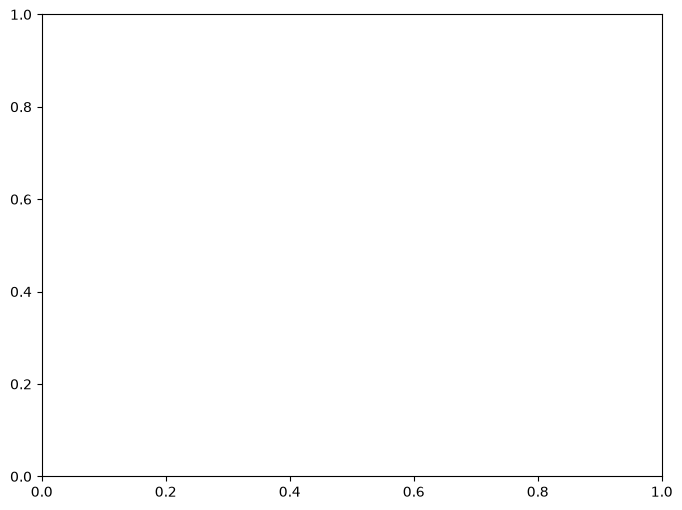

In [45]:
"""Sezione 11 — Esplorazione interna alla rete."""
try:
    SEED
except NameError:
    SEED = 42
set_seed(SEED)

import matplotlib.pyplot as plt
from sklearn.manifold import TSNE

# --- Estrai vettori latenti (media sulla dimensione temporale) ---
def get_latent(loader, n_samples=2000):
    model.eval()
    latents = []
    labels = []
    with torch.no_grad():
        for batch in loader:
            x = batch[0] if isinstance(batch, (list, tuple)) else batch
            x = x.to(DEVICE)
            z = model.encode(x)  # (B, latent_dim, W/4)
            z = z.mean(dim=2)  # (B, latent_dim) — vettore per finestra
            latents.append(z.cpu().numpy())
            labels.append(batch[1].cpu().numpy() if len(batch) > 1 else np.zeros(len(x)))
            if len(np.concatenate(latents)) >= n_samples:
                break
    return np.concatenate(latents)[:n_samples], np.concatenate(labels)[:n_samples]

z_norm, y_norm = get_latent(val_normal_loader, 2000)
z_anom, y_anom = get_latent(val_anomaly_loader, 2000)

z_all = np.vstack([z_norm, z_anom])
y_all = np.concatenate([y_norm, y_anom])

# --- t-SNE ---
tsne = TSNE(n_components=2, random_state=SEED, perplexity=30)
z_2d = tsne.fit_transform(z_all)

fig, ax = plt.subplots(1, 1, figsize=(8, 6))
ax.scatter(z_2d[y_all == 0, 0], z_2d[y_all == 0, 1], c="#2196F3", alpha=0.5, s=10, label="Normal")
ax.scatter(z_2d[y_all == 1, 0], z_2d[y_all == 1, 1], c="#FF5722", alpha=0.5, s=10, label="Anomaly")
ax.set_xlabel("t-SNE 1")
ax.set_ylabel("t-SNE 2")
ax.set_title("Spazio latente (t-SNE) — Validation")
ax.legend()
plt.tight_layout()
plt.show()

# --- Input vs Ricostruzione (3 normali + 3 anomalie) ---
err_norm_per_win = torch.abs(val_normal_loader.dataset.tensors[0] - model(val_normal_loader.dataset.tensors[0].to(DEVICE)).cpu()).mean(dim=(1,2))
err_anom_per_win = torch.abs(val_anomaly_loader.dataset.tensors[0] - model(val_anomaly_loader.dataset.tensors[0].to(DEVICE)).cpu()).mean(dim=(1,2))

norm_idx = torch.argsort(err_norm_per_win)[:3]
anom_idx = torch.argsort(err_anom_per_win)[:3]

fig, axes = plt.subplots(2, 6, figsize=(15, 4))
for j in range(3):
    x = val_normal_loader.dataset.tensors[0][norm_idx[j]].to(DEVICE).unsqueeze(0)
    x_pred = model(x)
    axes[0, j].imshow(x[0, :, 0].cpu().numpy(), aspect='auto', cmap='viridis')
    axes[0, j].set_title("Norm input %d" % j)
    axes[0, j].axis('off')
    axes[1, j].imshow(x_pred[0, :, 0].cpu().detach().numpy(), aspect='auto', cmap='viridis')
    axes[1, j].set_title("Norm recon %d" % j)
    axes[1, j].axis('off')

for j in range(3):
    x = val_anomaly_loader.dataset.tensors[0][anom_idx[j]].to(DEVICE).unsqueeze(0)
    x_pred = model(x)
    axes[0, j+3].imshow(x[0, :, 0].cpu().numpy(), aspect='auto', cmap='viridis')
    axes[0, j+3].set_title("Anom input %d" % j)
    axes[0, j+3].axis('off')
    axes[1, j+3].imshow(x_pred[0, :, 0].cpu().detach().numpy(), aspect='auto', cmap='viridis')
    axes[1, j+3].set_title("Anom recon %d" % j)
    axes[1, j+3].axis('off')

plt.tight_layout()
plt.show()


## Sezione 12 — Decisione finale: Lasciare così o gestire?

**Obiettivo:** raccogliere le evidenze di tutte le sezioni precedenti e prendere una decisione documentata.
**Criteri:**
- Fuori range concentrati in poche feature → gestire quelle feature
- Fuori range diffusi su molte feature → drift dati raw → lasciare così
- Delta AUC < 0.05 → impatto trascurabile → lasciare così
- Delta AUC > 0.10 → impatto rilevante → gestire (clipping/winsorizing/altro)
- Paradigma ricostruzione già giudicato non idoneo → problema architetturale

In [ ]:
"""Sezione 12 — Decisione finale: Lasciare così o gestire?"""
try:
    SEED
except NameError:
    SEED = 42
set_seed(SEED)

print("=" * 70)
print("DECISIONE FINALE: Lasciare così o gestire i fuori range?")
print("=" * 70)

# --- Analisi evidenze dalle sezioni precedenti ---
n_oob_features = 0
for split_name in splits_to_check:
    arr = scaled[split_name]
    feat_min = arr.min(axis=0)
    feat_max = arr.max(axis=0)
    n_oob = int(np.sum((feat_min < -1.0) | (feat_max > 1.0)))
    n_oob_features = max(n_oob_features, n_oob)

delta_auc = delta_test if 'delta_test' in dir() else 0

print("\n--- EVIDENZE RACCOLTE ---")
print("Feature fuori range (max per split): %d/%d" % (n_oob_features, input_dim))
print("Delta AUC test (CLIPPED - RAW): %+.4f" % delta_auc)

# --- Decisione ---
decisione = ""
motivazione = ""

if n_oob_features <= 3:
    decisione = "GESTIRE"
    motivazione = "Fuori range concentrati in poche feature → causa isolabile"
elif abs(delta_auc) < 0.05:
    decisione = "LASCIARE COSÌ"
    motivazione = "Impatto fuori range trascurabile (< 0.05)"
elif abs(delta_auc) > 0.10:
    decisione = "GESTIRE"
    motivazione = "Impatto fuori range rilevante (> 0.10) → causa principale mismatch val/test"
else:
    decisione = "LASCIARE COSÌ"
    motivazione = "Impatto moderato → il problema è più probabilmente architetturale (paradigma ricostruzione non idoneo)"

print("\n" + "=" * 70)
print("DECISIONE: %s" % decisione)
print("Motivazione: %s" % motivazione)
print("=" * 70)

print("\nFine notebook 04.")